<a href="https://colab.research.google.com/github/Minhhieu3012/wifi-localization-data-mining/blob/part4b-dbscan-report/notebooks/members/05_dbscan_evaluation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
## PHẦN 4B: GOM CỤM DỮ LIỆU VỚI DBSCAN, ĐÁNH GIÁ ARI VÀ TRỰC QUAN HÓA PCA 2D
**Phụ trách:** PHAN MINH HIẾU (`feature/part4b-dbscan-report`)
* **Mục tiêu:**
  1. Loại trừ cột nhãn `Room`, chuẩn hóa 7 thuộc tính liên tục bằng `StandardScaler`.
  2. Tìm tham số `eps` tối ưu bằng biểu đồ `k-distance` và thực hiện gom cụm bằng `DBSCAN`.
  3. Đánh giá kết quả gom cụm bằng độ đo **Adjusted Rand Index (ARI)** đối chiếu với `K-Means (k=4)`.
  4. Trực quan hóa kết quả gom cụm trên không gian giảm chiều **PCA 2D** (hiển thị rõ nhóm **Nhiễu / Noise** của DBSCAN).

In [ ]:
 ### 1. Loại trừ cột nhãn `Room`, chuẩn hóa 7 thuộc tính liên tục bằng `StandardScaler`.

In [3]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import adjusted_rand_score

# Cố định hạt giống ngẫu nhiên dùng chung cho toàn nhóm
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# Cấu hình hiển thị biểu đồ
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["font.size"] = 11
sns.set_theme(style="whitegrid", palette="deep")

# Đọc dữ liệu chuẩn
CSV_PATH = "wifi_localization.csv"
EXCEL_PATH = "D08 - wifi_localization.xlsx"
COLUMN_NAMES = ["WiFi_1", "WiFi_2", "WiFi_3", "WiFi_4", "WiFi_5", "WiFi_6", "WiFi_7", "Room"]
feature_cols = COLUMN_NAMES[:-1]

if os.path.exists(CSV_PATH):
    df = pd.read_csv(CSV_PATH)
elif os.path.exists(EXCEL_PATH):
    df = pd.read_excel(EXCEL_PATH, sheet_name="wifi_localization", header=None, names=COLUMN_NAMES)
    df.to_csv(CSV_PATH, index=False)
else:
    GITHUB_RAW_URL = "https://raw.githubusercontent.com/Minhhieu3012/wifi-localization-data-mining/main/data/processed/wifi_localization.csv"
    df = pd.read_csv(GITHUB_RAW_URL)

# Ép kiểu float64 cho 7 cột thuộc tính liên tục và int64 cho cột nhãn
df[feature_cols] = df[feature_cols].astype("float64")
df["Room"] = df["Room"].astype("int64")

# Loại trừ cột nhãn (Room) để lấy ma trận đặc trưng X cho bài toán gom cụm
X = df[feature_cols].values
y = df["Room"].values  # Chỉ giữ lại y để tính độ đo đánh giá Adjusted Rand Index (ARI)

# Chuẩn hóa dữ liệu với StandardScaler (Bắt buộc cho PCA, K-Means và DBSCAN)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Tạo tọa độ giảm chiều PCA 2D và nhãn K-Means
pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X_scaled)

kmeans = KMeans(n_clusters=4, random_state=RANDOM_STATE, n_init=10)
kmeans_labels = kmeans.fit_predict(X_scaled)

print("=== KIỂM TRA DỮ LIỆU KHỞI TẠO ===")
print(f"- Kích thước tập đặc trưng X (đã bỏ cột nhãn) : {X.shape}")
print(f"- Kích thước vector nhãn thực tế y            : {y.shape}")
print(f"- Trung bình và Độ lệch chuẩn của X_scaled    : mean = {X_scaled.mean():.4f}, std = {X_scaled.std():.4f}")
print(f"- Phương sai giữ lại trên không gian PCA 2D   : {pca.explained_variance_ratio_.sum()*100:.2f}% "
      f"(PC1: {pca.explained_variance_ratio_[0]*100:.2f}%, PC2: {pca.explained_variance_ratio_[1]*100:.2f}%)")
print(f"- Phân bố số điểm trong 4 cụm của K-Means     : {dict(zip(range(4), np.bincount(kmeans_labels)))}")

=== KIỂM TRA DỮ LIỆU KHỞI TẠO ===
- Kích thước tập đặc trưng X (đã bỏ cột nhãn) : (2000, 7)
- Kích thước vector nhãn thực tế y            : (2000,)
- Trung bình và Độ lệch chuẩn của X_scaled    : mean = 0.0000, std = 1.0000
- Phương sai giữ lại trên không gian PCA 2D   : 72.96% (PC1: 48.51%, PC2: 24.45%)
- Phân bố số điểm trong 4 cụm của K-Means     : {0: np.int64(477), 1: np.int64(450), 2: np.int64(503), 3: np.int64(570)}


In [ ]:
### 2. Tìm tham số `eps` tối ưu bằng biểu đồ `k-distance` và thực hiện gom cụm bằng `DBSCAN`.
* **Lựa chọn `min_samples`:** Với không gian đặc trưng $d = 7$ chiều, theo quy tắc kinh nghiệm chuẩn học thuật ($\text{min\_samples} \ge 2 \times d$), ta khảo sát tại 3 mức: $k = 10$, $k = 14$ ($2 \times 7$) và $k = 20$.
* **Nguyên lý biểu đồ k-distance:** Với mỗi điểm dữ liệu trong `X_scaled`, ta tính khoảng cách Euclid đến điểm láng giềng gần thứ $k$ của nó và sắp xếp theo thứ tự tăng dần.
  * Vùng đường cong thoải và thấp bên trái tương ứng với các điểm nằm sâu trong vùng lõi mật độ cao của 4 căn phòng (Core Points).
  * Vùng đường cong bắt đầu uốn cong và dốc vọt lên ở bên phải tương ứng với các điểm nằm ở rìa phòng (gần tường/vách ngăn) hoặc nhiễu đa đường (Noise).
  * Ngưỡng `eps` tối ưu để tách biệt 4 phòng nằm ở **đầu vùng khuỷu tay (khoảng `eps` từ `0.80` đến `0.90`)** trước khi hiệu ứng bắc cầu (chaining effect) xảy ra.

[min_samples = 10] Min: 0.3958 | Phân vị 50%: 0.8959 | Phân vị 60%: 0.9534 | Phân vị 75%: 1.0697 | Max: 3.6345
[min_samples = 14] Min: 0.4430 | Phân vị 50%: 0.9627 | Phân vị 60%: 1.0215 | Phân vị 75%: 1.1502 | Max: 3.9522
[min_samples = 20] Min: 0.5084 | Phân vị 50%: 1.0382 | Phân vị 60%: 1.1018 | Phân vị 75%: 1.2401 | Max: 4.3193


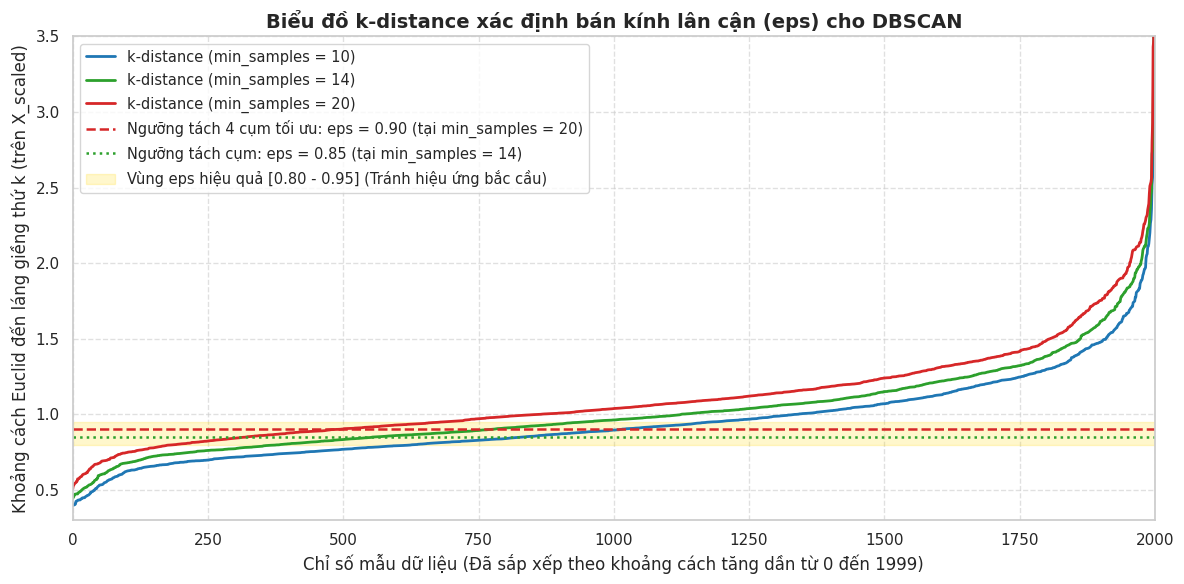

In [4]:
k_Candidates = [10, 14, 20]
colors = ["#1f77b4", "#2ca02c", "#d62728"]
k_distances_dict = {}

plt.figure(figsize=(12, 6))

for k, color in zip(k_Candidates, colors):
    # Tính khoảng cách đến k láng giềng gần nhất trên dữ liệu đã chuẩn hóa
    nbrs = NearestNeighbors(n_neighbors=k, metric="euclidean").fit(X_scaled)
    distances, _ = nbrs.kneighbors(X_scaled)

    # Lấy khoảng cách đến láng giềng thứ k (cột cuối cùng) và sắp xếp tăng dần
    k_dist = np.sort(distances[:, k - 1])
    k_distances_dict[k] = k_dist

    # Vẽ đường cong k-distance
    plt.plot(k_dist, label=f"k-distance (min_samples = {k})", color=color, linewidth=2)

    # In thống kê phân vị để đối chiếu học thuật
    print(f"[min_samples = {k:2d}] Min: {k_dist[0]:.4f} | "
          f"Phân vị 50%: {np.percentile(k_dist, 50):.4f} | "
          f"Phân vị 60%: {np.percentile(k_dist, 60):.4f} | "
          f"Phân vị 75%: {np.percentile(k_dist, 75):.4f} | "
          f"Max: {k_dist[-1]:.4f}")

# Đánh dấu các ngưỡng eps quan trọng trên đồ thị
plt.axhline(y=0.90, color="#d62728", linestyle="--", linewidth=1.8,
            label="Ngưỡng tách 4 cụm tối ưu: eps = 0.90 (tại min_samples = 20)")
plt.axhline(y=0.85, color="#2ca02c", linestyle=":", linewidth=1.8,
            label="Ngưỡng tách cụm: eps = 0.85 (tại min_samples = 14)")
plt.axhspan(0.80, 0.95, color="gold", alpha=0.2,
            label="Vùng eps hiệu quả [0.80 - 0.95] (Tránh hiệu ứng bắc cầu)")

plt.title("Biểu đồ k-distance xác định bán kính lân cận (eps) cho DBSCAN", fontsize=14, fontweight="bold")
plt.xlabel("Chỉ số mẫu dữ liệu (Đã sắp xếp theo khoảng cách tăng dần từ 0 đến 1999)", fontsize=12)
plt.ylabel("Khoảng cách Euclid đến láng giềng thứ k (trên X_scaled)", fontsize=12)
plt.xlim(0, len(X_scaled))
plt.ylim(0.3, 3.5)
plt.legend(loc="upper left", frameon=True, fontsize=10.5)
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()